# CSAI4014: Algorithms for Intelligent Systems and Robotics
## Experiment 6: A Simple Neural Network
**Student Name:** Aditya Pratap Singh Sisodia  
**SAP ID:** 500121985 | **Roll No:** R2142230333  
**Batch:** [Batch A/B/D]  
**Academic Year:** 2026–2027 (Autumn Semester)
---


### 1. XOR Neural Network: Pure NumPy Multilayer Perceptron
A 2-4-1 network with sigmoid activations trained using analytical backpropagation on the non-linearly separable XOR problem.

=== Table 6.1: Network and Training Set-up ===
Architecture: 2 Inputs -> 4 Hidden Neurons -> 1 Output Neuron
Activation: Sigmoid (Hidden and Output)
Loss function: Mean Squared Error (MSE)
Optimizer: Batch Gradient Descent (NumPy implementation)
Training epochs: 25,000 | Random Seed: 174

=== Table 6.2: Effect of Learning Rate ===
 Learning Rate (η) | Final MSE Loss | Converged? (Loss < 0.01) | Epochs to Converge
---------------------------------------------------------------------------
 η = 0.05          |       0.001305 | Yes                      | 7,891
 η = 0.50          |       0.000086 | Yes                      | 790
 η = 2.00          |       0.000020 | Yes                      | 198

=== Table 6.3: Predicted Outputs After Training (Best Run: η = 2.0) ===
 Input (x1, x2) | Target (y) | Predicted Output (o) | Rounded Class
-----------------------------------------------------------------
   (0, 0)      |    0     |       0.00297        |       0
   (0, 1)      |    1     |     

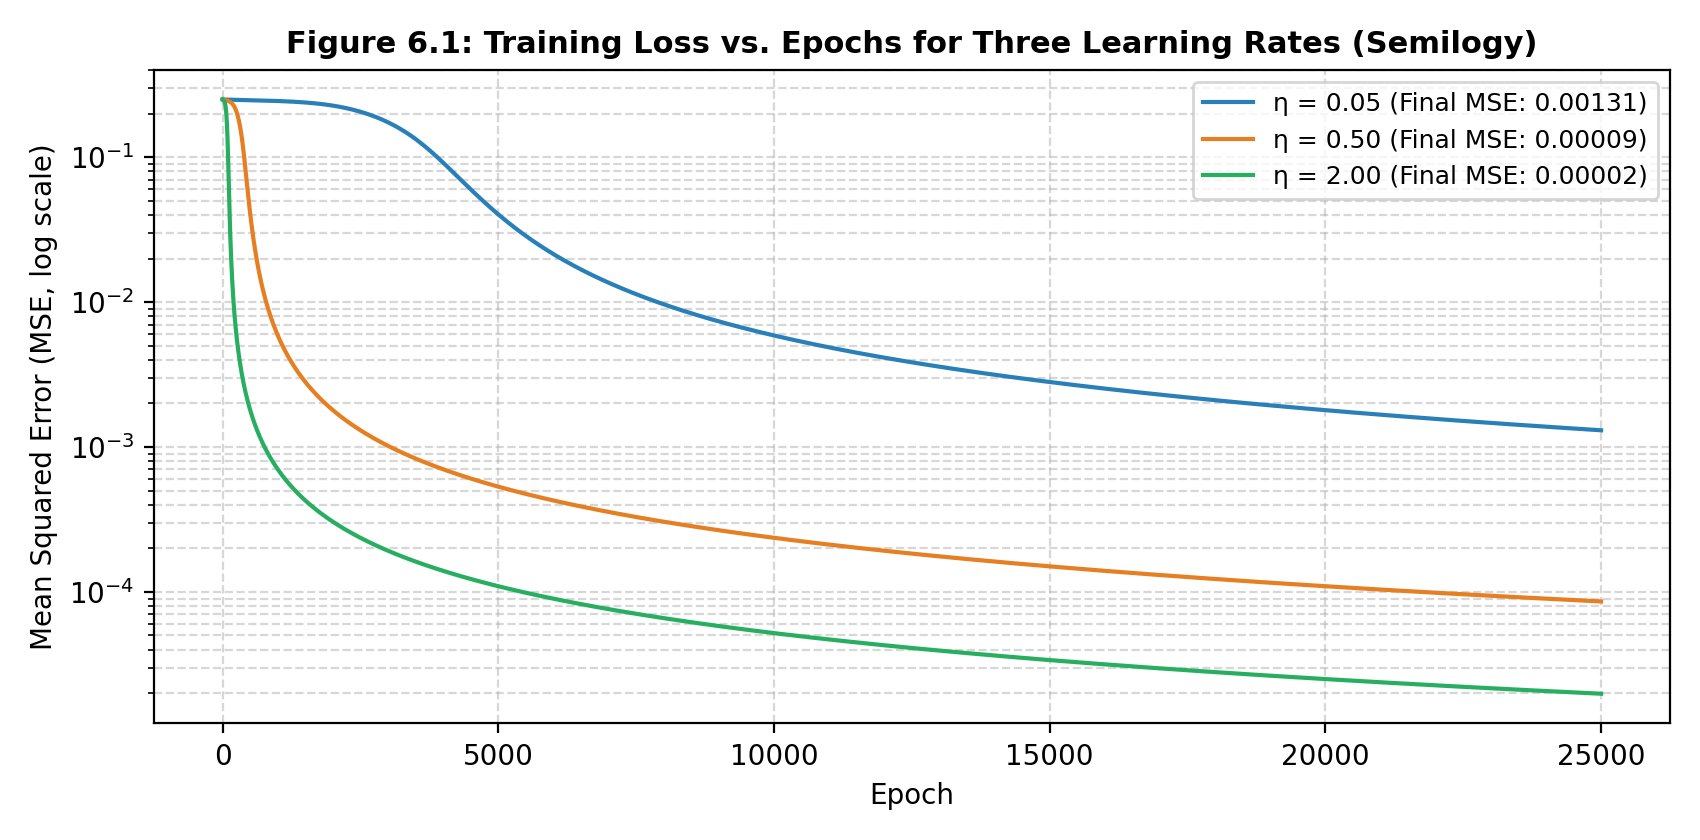

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np

base_dir = r"c:\Users\91976\Desktop\AISR\aisr-lab-500121985\exp06-neural"
figs_dir = os.path.join(base_dir, "figs")
os.makedirs(figs_dir, exist_ok=True)

# -------------------------------------------------------------
# Part 1: XOR Data and Activation Functions
# -------------------------------------------------------------
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)  # XOR logic gate

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))

def sigmoid_deriv(a):
    return a * (1.0 - a)

# -------------------------------------------------------------
# Part 2: MLP Training via Backpropagation (Pure NumPy)
# -------------------------------------------------------------
def train_xor_mlp(lr, epochs=25000, seed=174, hidden=4):
    rng = np.random.default_rng(seed)
    # Weights initialization (small random normal)
    W1 = rng.normal(0, 1.0, (2, hidden))
    b1 = np.zeros((1, hidden))
    W2 = rng.normal(0, 1.0, (hidden, 1))
    b2 = np.zeros((1, 1))

    losses = []
    converged_epoch = None

    for epoch in range(epochs):
        # Forward pass
        z1 = X @ W1 + b1
        h = sigmoid(z1)  # Hidden activations: (4, hidden)
        z2 = h @ W2 + b2
        o = sigmoid(z2)  # Output activations: (4, 1)

        loss = float(np.mean((o - y) ** 2))
        losses.append(loss)

        if converged_epoch is None and loss < 0.01:
            converged_epoch = epoch

        # Backward pass (Analytical gradient computation)
        # dL/do = 2 * (o - y) / 4 = 0.5 * (o - y); using delta = (o - y) * o*(1 - o)
        do = (o - y) * sigmoid_deriv(o)
        dh = (do @ W2.T) * sigmoid_deriv(h)

        # Gradient descent update
        W2 -= lr * (h.T @ do)
        b2 -= lr * np.sum(do, axis=0, keepdims=True)
        W1 -= lr * (X.T @ dh)
        b1 -= lr * np.sum(dh, axis=0, keepdims=True)

    return {
        'W1': W1, 'b1': b1, 'W2': W2, 'b2': b2,
        'losses': losses, 'final_loss': losses[-1],
        'converged': converged_epoch is not None,
        'converged_epoch': converged_epoch,
        'final_output': o
    }

# -------------------------------------------------------------
# Part 3: Evaluate Effect of Learning Rates
# -------------------------------------------------------------
lrs = [0.05, 0.5, 2.0]
results = {}

print("=== Table 6.1: Network and Training Set-up ===")
print("Architecture: 2 Inputs -> 4 Hidden Neurons -> 1 Output Neuron")
print("Activation: Sigmoid (Hidden and Output)")
print("Loss function: Mean Squared Error (MSE)")
print("Optimizer: Batch Gradient Descent (NumPy implementation)")
print("Training epochs: 25,000 | Random Seed: 174")

print("\n=== Table 6.2: Effect of Learning Rate ===")
print(" Learning Rate (η) | Final MSE Loss | Converged? (Loss < 0.01) | Epochs to Converge")
print("-" * 75)

for lr in lrs:
    res = train_xor_mlp(lr, epochs=25000, seed=174)
    results[lr] = res
    conv_str = "Yes" if res['converged'] else "No"
    conv_ep = f"{res['converged_epoch']:,}" if res['converged'] else "Did not reach < 0.01"
    print(f" η = {lr:4.2f}          | {res['final_loss']:14.6f} | {conv_str:24s} | {conv_ep}")

# Best run predictions
best_lr = 2.0
best_model = results[best_lr]
pred_best = best_model['final_output']

print(f"\n=== Table 6.3: Predicted Outputs After Training (Best Run: η = {best_lr}) ===")
print(" Input (x1, x2) | Target (y) | Predicted Output (o) | Rounded Class")
print("-" * 65)
for (x1, x2), target, pred in zip(X, y.flatten(), pred_best.flatten()):
    print(f"   ({int(x1)}, {int(x2)})      |    {int(target)}     |       {pred:.5f}        |       {int(np.round(pred))}")

# -------------------------------------------------------------


### 2. Decision Boundary Over Continuous Input Plane
Contour visualization of the trained network's non-linear decision boundary separating the XOR classes.

Saved fig6_1_loss_curves.png and fig6_2_decision_boundary.png successfully.


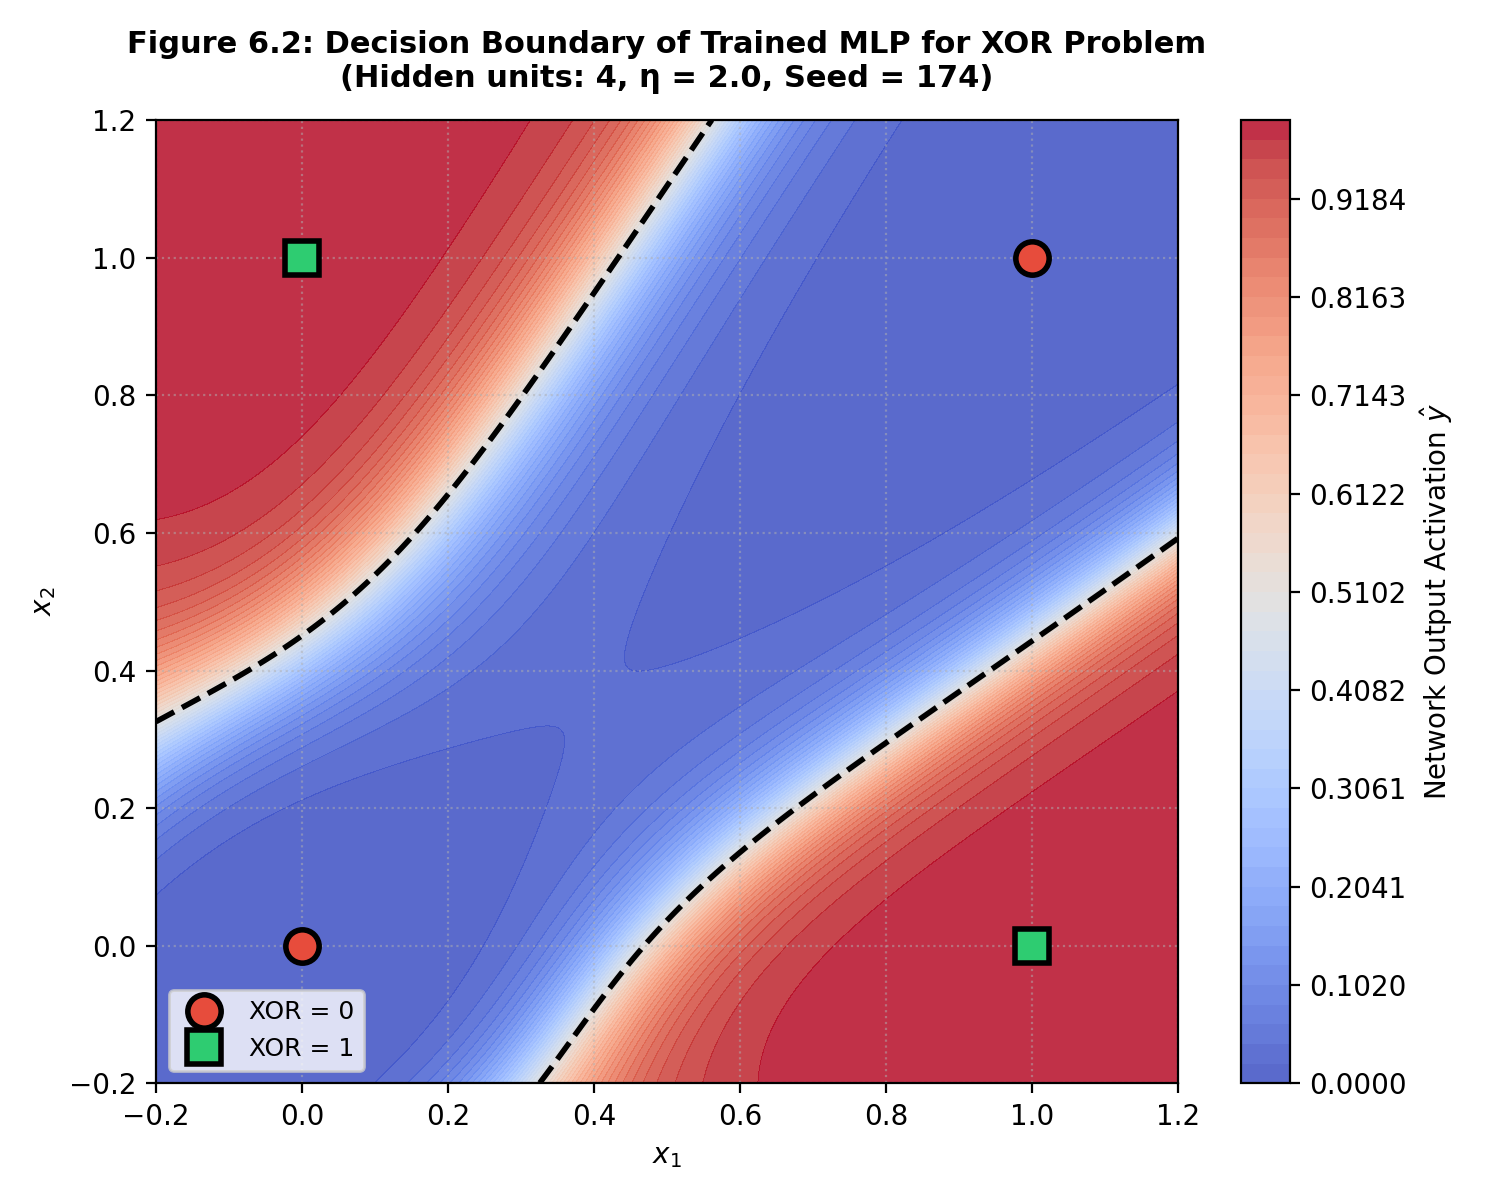

In [2]:
# Figure 6.1: Loss Curves
# -------------------------------------------------------------
plt.figure(figsize=(8.5, 4.2), dpi=200)
colors = ['#2980b9', '#e67e22', '#27ae60']

for lr, col in zip(lrs, colors):
    plt.semilogy(results[lr]['losses'], color=col, lw=1.5,
                 label=f'η = {lr:.2f} (Final MSE: {results[lr]["final_loss"]:.5f})')

plt.title('Figure 6.1: Training Loss vs. Epochs for Three Learning Rates (Semilogy)', fontsize=11, fontweight='bold')
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Mean Squared Error (MSE, log scale)', fontsize=10)
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(figs_dir, "fig6_1_loss_curves.png"))
plt.close()

# -------------------------------------------------------------
# Figure 6.2: Decision Boundary Over Input Plane
# -------------------------------------------------------------
gx = np.linspace(-0.2, 1.2, 300)
gy = np.linspace(-0.2, 1.2, 300)
xx, yy = np.meshgrid(gx, gy)
grid_pts = np.c_[xx.ravel(), yy.ravel()]

# Forward pass on dense grid
h_grid = sigmoid(grid_pts @ best_model['W1'] + best_model['b1'])
o_grid = sigmoid(h_grid @ best_model['W2'] + best_model['b2']).reshape(xx.shape)

plt.figure(figsize=(7.5, 6.0), dpi=200)
cf = plt.contourf(xx, yy, o_grid, levels=np.linspace(0, 1, 50), cmap='coolwarm', alpha=0.85)
cbar = plt.colorbar(cf)
cbar.set_label('Network Output Activation $\hat{y}$', fontsize=10)

# Decision boundary contour line at 0.5
plt.contour(xx, yy, o_grid, levels=[0.5], colors='black', linewidths=2.0, linestyles='--')

# Plot training points
for (x1, x2), target in zip(X, y.flatten()):
    if target == 1:
        plt.plot(x1, x2, 's', color='#2ecc71', ms=12, mew=2, mec='black', label='XOR = 1' if (x1, x2) == (0, 1) else "")
    else:
        plt.plot(x1, x2, 'o', color='#e74c3c', ms=12, mew=2, mec='black', label='XOR = 0' if (x1, x2) == (0, 0) else "")

plt.title(f'Figure 6.2: Decision Boundary of Trained MLP for XOR Problem\n(Hidden units: 4, η = {best_lr}, Seed = 174)',
          fontsize=11, fontweight='bold', pad=12)
plt.xlabel('$x_1$', fontsize=10)
plt.ylabel('$x_2$', fontsize=10)
plt.xlim(-0.2, 1.2)
plt.ylim(-0.2, 1.2)
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(loc='lower left', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(figs_dir, "fig6_2_decision_boundary.png"))
plt.close()

print("\nSaved fig6_1_loss_curves.png and fig6_2_decision_boundary.png successfully.")
